<a href="https://colab.research.google.com/github/IvMatic/fraud-ring-detection-ml/blob/main/notebooks/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import drive
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

drive.mount("/content/drive")

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/fraud-ring-detection-ml"
)

RAW_DATA_PATH = PROJECT_ROOT / "data/raw"
RAW_DATA_PATH.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

print("Project ready:", PROJECT_ROOT)


Mounted at /content/drive
Project ready: /content/drive/MyDrive/fraud-ring-detection-ml


In [2]:

N_ACCOUNTS = 1000
N_UNUSUAL = 30
N_NORMAL = N_ACCOUNTS - N_UNUSUAL

# Simulated regular accounts
normal = pd.DataFrame({
    "num_devices": rng.poisson(2, N_NORMAL),
    "num_transactions_24h": rng.poisson(8, N_NORMAL),
    "connected_accounts": rng.poisson(3, N_NORMAL)
})

# Simulated unusual accounts
unusual = pd.DataFrame({
    "num_devices": rng.integers(8, 20, N_UNUSUAL),
    "num_transactions_24h": rng.integers(50, 150, N_UNUSUAL),
    "connected_accounts": rng.integers(20, 60, N_UNUSUAL)
})

# Ground truth for synthetic experiments
normal["is_synthetic_anomaly"] = 0
unusual["is_synthetic_anomaly"] = 1

# Combine and shuffle rows
df = pd.concat([normal, unusual], ignore_index=True)

df = df.sample(
    frac=1,
    random_state=RANDOM_STATE
).reset_index(drop=True)

df.insert(
    0,
    "account_id",
    [f"ACC_{i:05d}" for i in range(1, len(df) + 1)]
)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (1000, 5)


,account_id,num_devices,num_transactions_24h,connected_accounts,is_synthetic_anomaly
0,ACC_00001,0,12,5,0
1,ACC_00002,0,17,4,0
2,ACC_00003,3,9,1,0
3,ACC_00004,2,9,4,0
4,ACC_00005,2,9,4,0


In [3]:

file_path = RAW_DATA_PATH / "synthetic_accounts_v1.csv"

df.to_csv(file_path, index=False)

print("Dataset saved to:", file_path)
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Synthetic anomalies:", df["is_synthetic_anomaly"].sum())


Dataset saved to: /content/drive/MyDrive/fraud-ring-detection-ml/data/raw/synthetic_accounts_v1.csv
Rows: 1000
Columns: 5
Synthetic anomalies: 30


In [4]:

print("Dataset information:")
df.info()

print("\nSummary statistics:")
display(df.describe())

print("\nMissing values:")
display(df.isnull().sum())

print("\nSynthetic anomaly distribution:")
display(df["is_synthetic_anomaly"].value_counts())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   account_id            1000 non-null   object
 1   num_devices           1000 non-null   int64 
 2   num_transactions_24h  1000 non-null   int64 
 3   connected_accounts    1000 non-null   int64 
 4   is_synthetic_anomaly  1000 non-null   int64 
dtypes: int64(4), object(1)
memory usage: 39.2+ KB

Summary statistics:


,num_devices,num_transactions_24h,connected_accounts,is_synthetic_anomaly
count,1000.000000,1000.00000,1000.00000,1000.000000
mean,2.324000,10.66300,4.14200,0.030000
std,2.333767,16.90542,6.65403,0.170673
min,0.000000,1.00000,0.00000,0.000000
25%,1.000000,6.00000,2.00000,0.000000
50%,2.000000,8.00000,3.00000,0.000000
75%,3.000000,10.00000,4.00000,0.000000
max,19.000000,149.00000,59.00000,1.000000



Missing values:


,0
account_id,0
num_devices,0
num_transactions_24h,0
connected_accounts,0
is_synthetic_anomaly,0



Synthetic anomaly distribution:


,count
is_synthetic_anomaly,
0,970
1,30



## 2. Exploratory Data Analysis

### Feature Distributions

We analyze the distributions of three numerical features
to understand typical account behavior and identify
potential outliers before training an anomaly detection model.


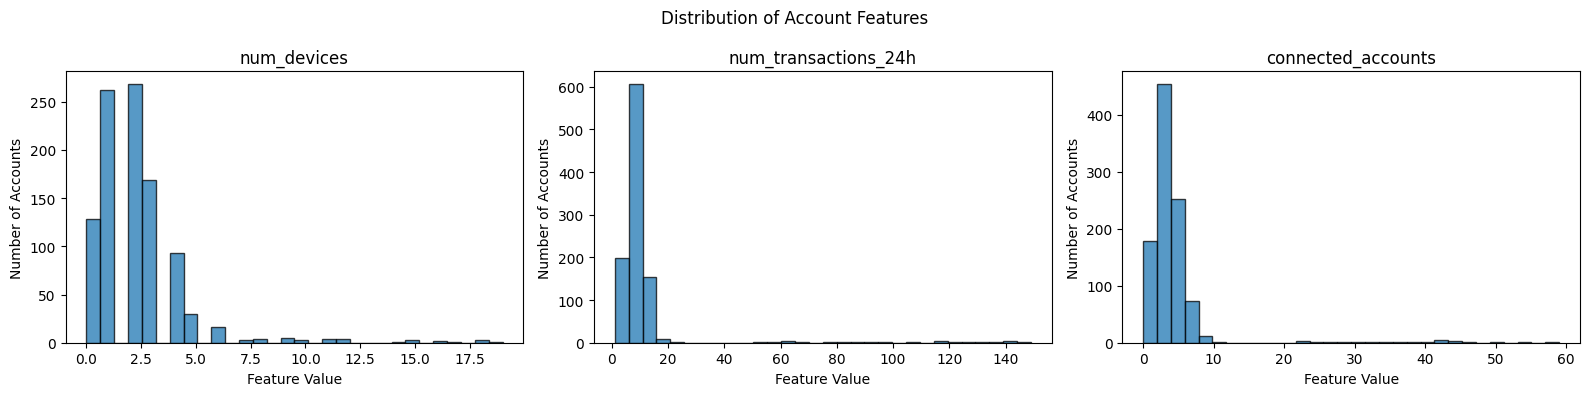

In [5]:

features = [
    "num_devices",
    "num_transactions_24h",
    "connected_accounts"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, feature in zip(axes, features):
    ax.hist(
        df[feature],
        bins=30,
        edgecolor="black",
        alpha=0.75
    )

    ax.set_title(feature)
    ax.set_xlabel("Feature Value")
    ax.set_ylabel("Number of Accounts")

plt.suptitle("Distribution of Account Features")
plt.tight_layout()
plt.show()


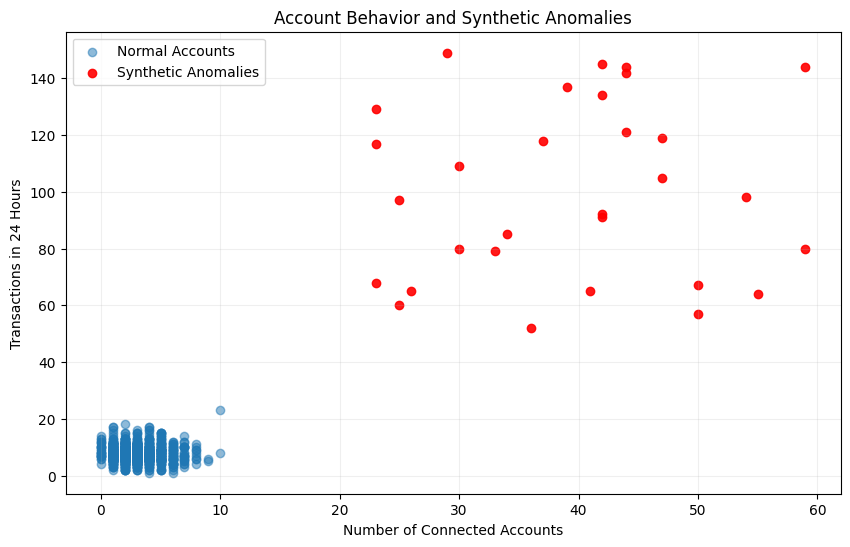

In [6]:

plt.figure(figsize=(10, 6))

normal = df[df["is_synthetic_anomaly"] == 0]
anomalies = df[df["is_synthetic_anomaly"] == 1]

plt.scatter(
    normal["connected_accounts"],
    normal["num_transactions_24h"],
    alpha=0.5,
    label="Normal Accounts"
)

plt.scatter(
    anomalies["connected_accounts"],
    anomalies["num_transactions_24h"],
    alpha=0.9,
    color="red",
    label="Synthetic Anomalies"
)

plt.xlabel("Number of Connected Accounts")
plt.ylabel("Transactions in 24 Hours")
plt.title("Account Behavior and Synthetic Anomalies")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


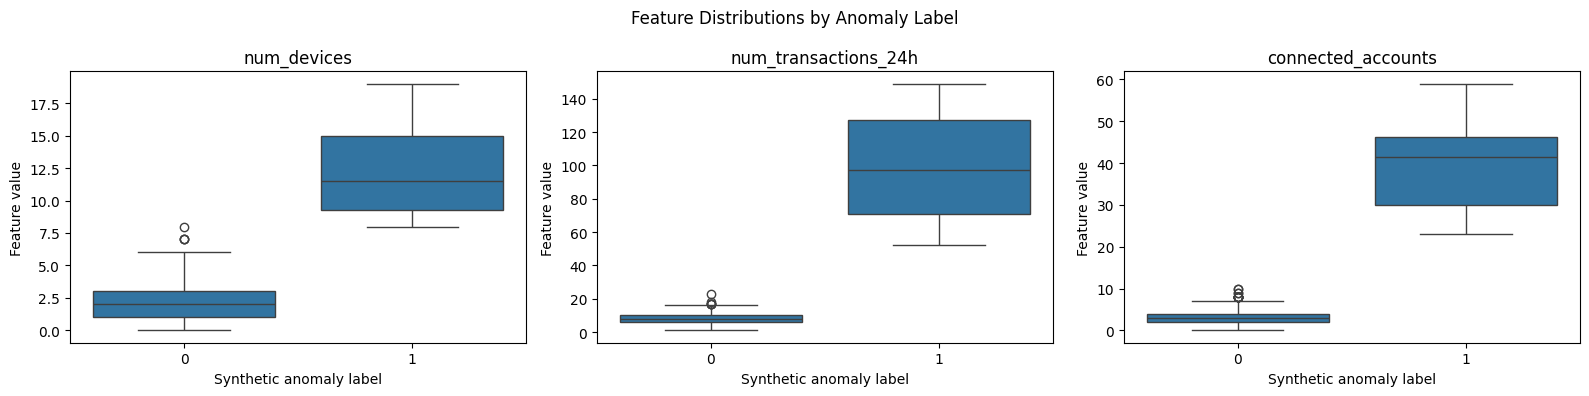

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

features = [
    "num_devices",
    "num_transactions_24h",
    "connected_accounts"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, feature in zip(axes, features):
    sns.boxplot(
        data=df,
        x="is_synthetic_anomaly",
        y=feature,
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xlabel("Synthetic anomaly label")
    ax.set_ylabel("Feature value")

plt.suptitle("Feature Distributions by Anomaly Label")
plt.tight_layout()
plt.show()


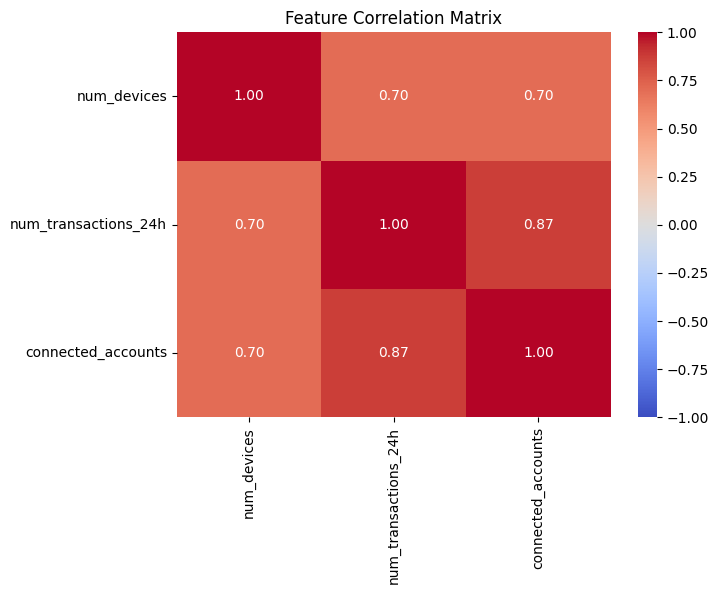

In [8]:

correlation_matrix = df[features].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Feature Correlation Matrix")
plt.show()


In [9]:

print("Duplicate account IDs:",
      df["account_id"].duplicated().sum())

print("Missing values:")
print(df.isna().sum())

print("Negative values:")
print((df[features] < 0).sum())

print("Anomaly percentage:")
print(df["is_synthetic_anomaly"].mean() * 100)


Duplicate account IDs: 0
Missing values:
account_id              0
num_devices             0
num_transactions_24h    0
connected_accounts      0
is_synthetic_anomaly    0
dtype: int64
Negative values:
num_devices             0
num_transactions_24h    0
connected_accounts      0
dtype: int64
Anomaly percentage:
3.0


Correlation matrix - normal accounts:


,num_devices,num_transactions_24h,connected_accounts
num_devices,1.000000,0.024754,-0.032456
num_transactions_24h,0.024754,1.000000,-0.039393
connected_accounts,-0.032456,-0.039393,1.000000


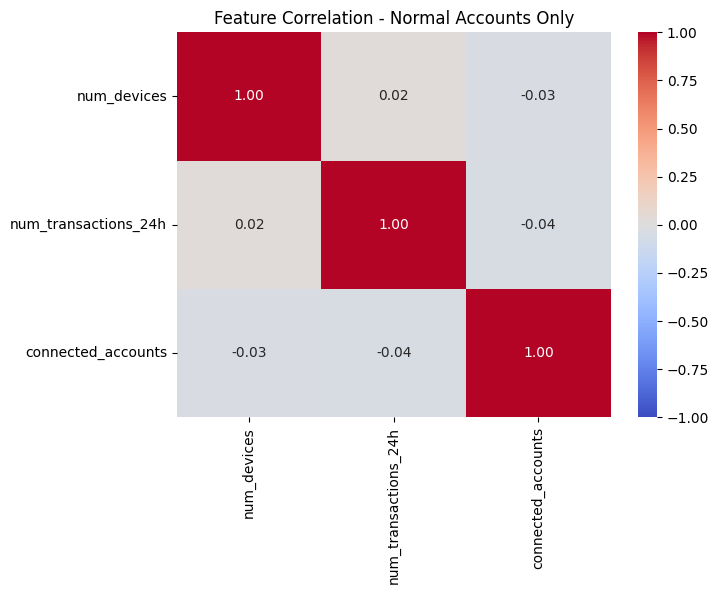

In [10]:

# Select only normal accounts
normal_df = df[df["is_synthetic_anomaly"] == 0]

# Correlation matrix for normal accounts only
normal_corr = normal_df[features].corr()

print("Correlation matrix - normal accounts:")
display(normal_corr)

# Visualization
plt.figure(figsize=(7, 5))

sns.heatmap(
    normal_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Feature Correlation - Normal Accounts Only")
plt.show()



## Findings and Interpretation

### 1. Dataset Overview

The dataset contains 1,000 synthetic bank accounts:
- 970 normal accounts
- 30 artificially generated anomalies
- 3 numerical features
- No missing values

### 2. Feature Distributions

Exploratory analysis revealed clear differences
between normal and anomalous accounts.

Anomalous accounts showed substantially higher
values in all three numerical features.

### 3. Correlation Analysis

Strong positive correlations were observed when
analyzing the complete dataset.

However, correlations among normal accounts
were close to zero:

- Devices vs. Transactions: 0.02
- Devices vs. Connected Accounts: -0.03
- Transactions vs. Connected Accounts: -0.04

This suggests that the strong overall correlations
were largely driven by differences between the
synthetically generated groups.

### 4. Key Learnings

- Feature distributions should be explored before
  training machine learning models.
- Overall correlations can be misleading when
  different populations are combined.
- Synthetic anomaly generation strongly influences
  model difficulty and evaluation results.

### 5. Limitations

- The dataset is synthetic.
- Anomalous accounts were deliberately generated
  with extreme feature values.
- The dataset does not represent realistic fraud rings.
- The features are aggregated numerical attributes,
  not actual graph relationships.

### 6. Next Steps

- Train and evaluate Isolation Forest.
- Introduce more challenging synthetic anomalies.
- Explore graph-based feature engineering.
